<a href="https://colab.research.google.com/github/Pujasatish001/DS-Lab-Experiments/blob/main/DS_Lab_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

House Price Dataset:
   Area  Bedrooms  Age  Distance  Price
0  1000         2   10        10     30
1  1200         2    8         8     35
2  1500         3    5         7     45
3  1800         3    7         6     50
4  2000         3    4         5     55
5  2200         4    3         4     65
6  2500         4    6         5     68
7  2800         4    2         3     78
8  3000         5    1         2     85
9  3200         5    3         3     90

Correlation with Price:
Area        0.996921
Bedrooms    0.977067
Age        -0.864725
Distance   -0.954168
Price       1.000000
Name: Price, dtype: float64


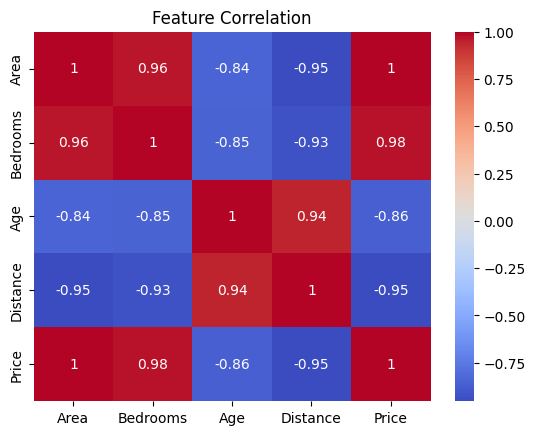


Simple Linear Regression
Slope: 0.02681046676096182
Intercept: 3.152758132956137


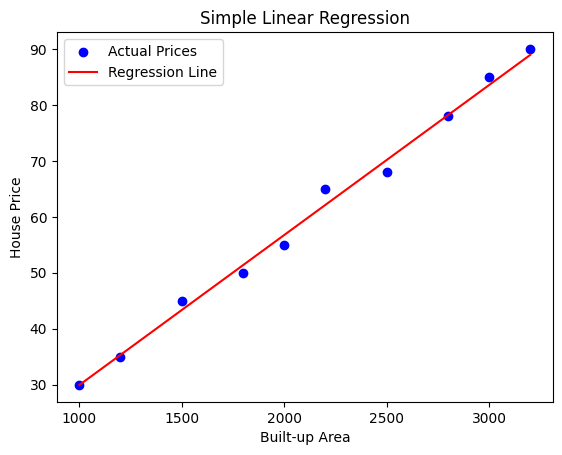


Multiple Linear Regression
Area Coefficient: 0.021992274263640754
Bedrooms Coefficient: 4.304683727667797
Age Coefficient: -0.8585224529212936
Distance Coefficient: 0.981844519555767
Intercept: -2.659777885079677

Model Evaluation:
MAE: 1.3093674553355932
MSE: 1.8467479746638253
RMSE: 1.3589510567580516
R-Squared: 0.9970452032405379

Predicted House Price: 68.69222597778852 Lakhs


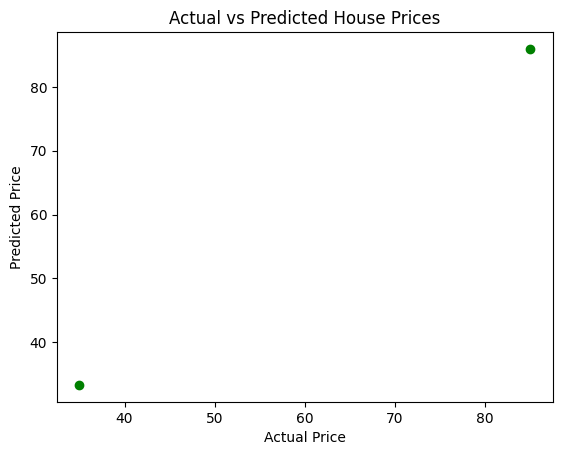

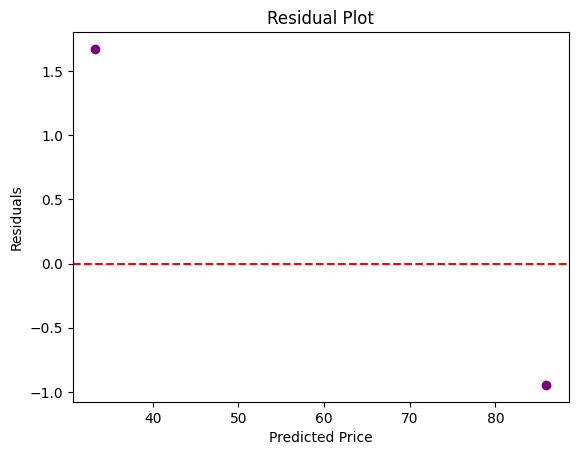

In [1]:

# Experiment 5: Linear Regression for House Price Prediction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Create Dataset
data = {
    'Area': [1000, 1200, 1500, 1800, 2000, 2200, 2500, 2800, 3000, 3200],
    'Bedrooms': [2, 2, 3, 3, 3, 4, 4, 4, 5, 5],
    'Age': [10, 8, 5, 7, 4, 3, 6, 2, 1, 3],
    'Distance': [10, 8, 7, 6, 5, 4, 5, 3, 2, 3],
    'Price': [30, 35, 45, 50, 55, 65, 68, 78, 85, 90]
}

df = pd.DataFrame(data)

print("House Price Dataset:")
print(df)

# 2. Correlation Analysis
print("\nCorrelation with Price:")
print(df.corr()['Price'])

sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Feature Correlation")
plt.show()

# 3. Simple Linear Regression (Price vs Area)
X = df[['Area']]
y = df['Price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_train, y_train)

print("\nSimple Linear Regression")
print("Slope:", simple_model.coef_[0])
print("Intercept:", simple_model.intercept_)

# Plot fitted line
plt.scatter(X, y, color='blue', label='Actual Prices')
plt.plot(X, simple_model.predict(X), color='red', label='Regression Line')
plt.xlabel("Built-up Area")
plt.ylabel("House Price")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

# 4. Multiple Linear Regression
X = df[['Area', 'Bedrooms', 'Age', 'Distance']]
y = df['Price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("\nMultiple Linear Regression")
for feature, coef in zip(X.columns, model.coef_):
    print(feature, "Coefficient:", coef)

print("Intercept:", model.intercept_)

# 5. Model Evaluation
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation:")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-Squared:", r2)

# 6. Predict Price of a New House
new_house = pd.DataFrame({
    'Area': [2400],
    'Bedrooms': [4],
    'Age': [3],
    'Distance': [4]
})

predicted_price = model.predict(new_house)

print("\nPredicted House Price:", predicted_price[0], "Lakhs")

# 7. Plot Actual vs Predicted Prices
plt.scatter(y_test, y_pred, color='green')
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")
plt.show()

# 8. Residual Plot
residuals = y_test - y_pred

plt.scatter(y_pred, residuals, color='purple')
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()


Customer Dataset:
   Tenure  MonthlyBill  Complaints  ContractType  Churn
0      39         1312           4             0      1
1      52          945           3             1      0
2      29         1095           3             0      0
3      15         1351           3             0      0
4      43          489           4             0      1

Logistic Regression Model Trained Successfully

Coefficients and Odds Ratios:
Tenure
Coefficient: -0.6508
Odds Ratio: 0.5216
MonthlyBill
Coefficient: 0.7895
Odds Ratio: 2.2024
Complaints
Coefficient: 1.4159
Odds Ratio: 4.1202
ContractType
Coefficient: -0.6539
Odds Ratio: 0.52

Model Evaluation:
Accuracy: 0.625
Precision: 0.6333333333333333
Recall: 0.8260869565217391
F1 Score: 0.7169811320754716
ROC-AUC: 0.6879795396419437


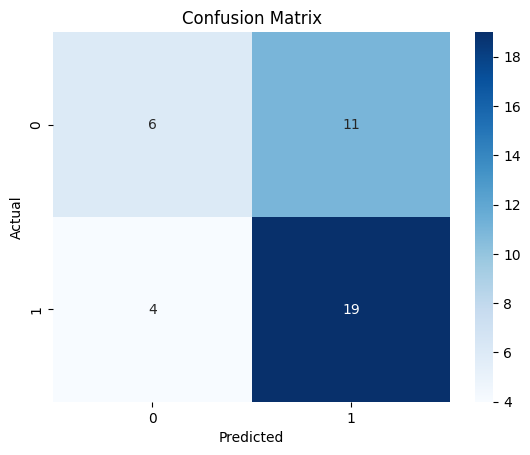


5-Fold Cross Validation Scores:
[0.78125 0.84375 0.71875 0.78125 0.8125 ]
Average Accuracy: 0.7875

New Customer Churn Prediction:
Churn Probability: 96.52 %
Prediction: Customer is likely to Churn


In [2]:

# Experiment 6: Logistic Regression for Customer Churn Prediction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score
)

# 1. Create Dataset
np.random.seed(42)

n = 200

data = pd.DataFrame({
    'Tenure': np.random.randint(1, 60, n),
    'MonthlyBill': np.random.randint(300, 1500, n),
    'Complaints': np.random.randint(0, 8, n),
    'ContractType': np.random.choice([0, 1], n)
})

# Generate churn values
z = (-1.5 - 0.04 * data['Tenure']
     + 0.002 * data['MonthlyBill']
     + 0.5 * data['Complaints']
     - 1.0 * data['ContractType'])

probability = 1 / (1 + np.exp(-z))

data['Churn'] = np.random.binomial(1, probability)

print("Customer Dataset:")
print(data.head())

# 2. Split Data into Training and Testing Sets
X = data[['Tenure', 'MonthlyBill', 'Complaints', 'ContractType']]
y = data['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Standardize Features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Train Logistic Regression Model
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

print("\nLogistic Regression Model Trained Successfully")

# 5. Display Coefficients and Odds Ratios
print("\nCoefficients and Odds Ratios:")

for feature, coef in zip(X.columns, model.coef_[0]):
    odds_ratio = np.exp(coef)
    print(feature)
    print("Coefficient:", round(coef, 4))
    print("Odds Ratio:", round(odds_ratio, 4))

# 6. Make Predictions
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# 7. Evaluate Model
print("\nModel Evaluation:")

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

# 8. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# 9. 5-Fold Cross Validation
cv_scores = cross_val_score(
    model, X_train_scaled, y_train, cv=5, scoring='accuracy'
)

print("\n5-Fold Cross Validation Scores:")
print(cv_scores)
print("Average Accuracy:", cv_scores.mean())

# 10. Predict Churn Probability of a New Customer
new_customer = pd.DataFrame({
    'Tenure': [12],
    'MonthlyBill': [1200],
    'Complaints': [5],
    'ContractType': [0]
})

new_customer_scaled = scaler.transform(new_customer)

churn_probability = model.predict_proba(new_customer_scaled)[0][1]

print("\nNew Customer Churn Prediction:")
print("Churn Probability:", round(churn_probability * 100, 2), "%")

if churn_probability >= 0.5:
    print("Prediction: Customer is likely to Churn")
else:
    print("Prediction: Customer is likely to Stay")


Wine Dataset:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  
0    

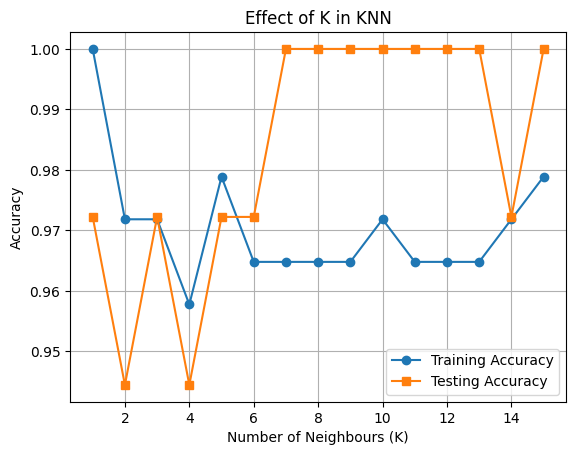


Decision Tree Rules:
|--- color_intensity <= 3.82
|   |--- ash <= 3.00
|   |   |--- od280/od315_of_diluted_wines <= 3.73
|   |   |   |--- class: 1
|   |   |--- od280/od315_of_diluted_wines >  3.73
|   |   |   |--- class: 0
|   |--- ash >  3.00
|   |   |--- class: 0
|--- color_intensity >  3.82
|   |--- flavanoids <= 1.58
|   |   |--- alcalinity_of_ash <= 17.65
|   |   |   |--- class: 1
|   |   |--- alcalinity_of_ash >  17.65
|   |   |   |--- class: 2
|   |--- flavanoids >  1.58
|   |   |--- proline <= 724.50
|   |   |   |--- class: 1
|   |   |--- proline >  724.50
|   |   |   |--- class: 0



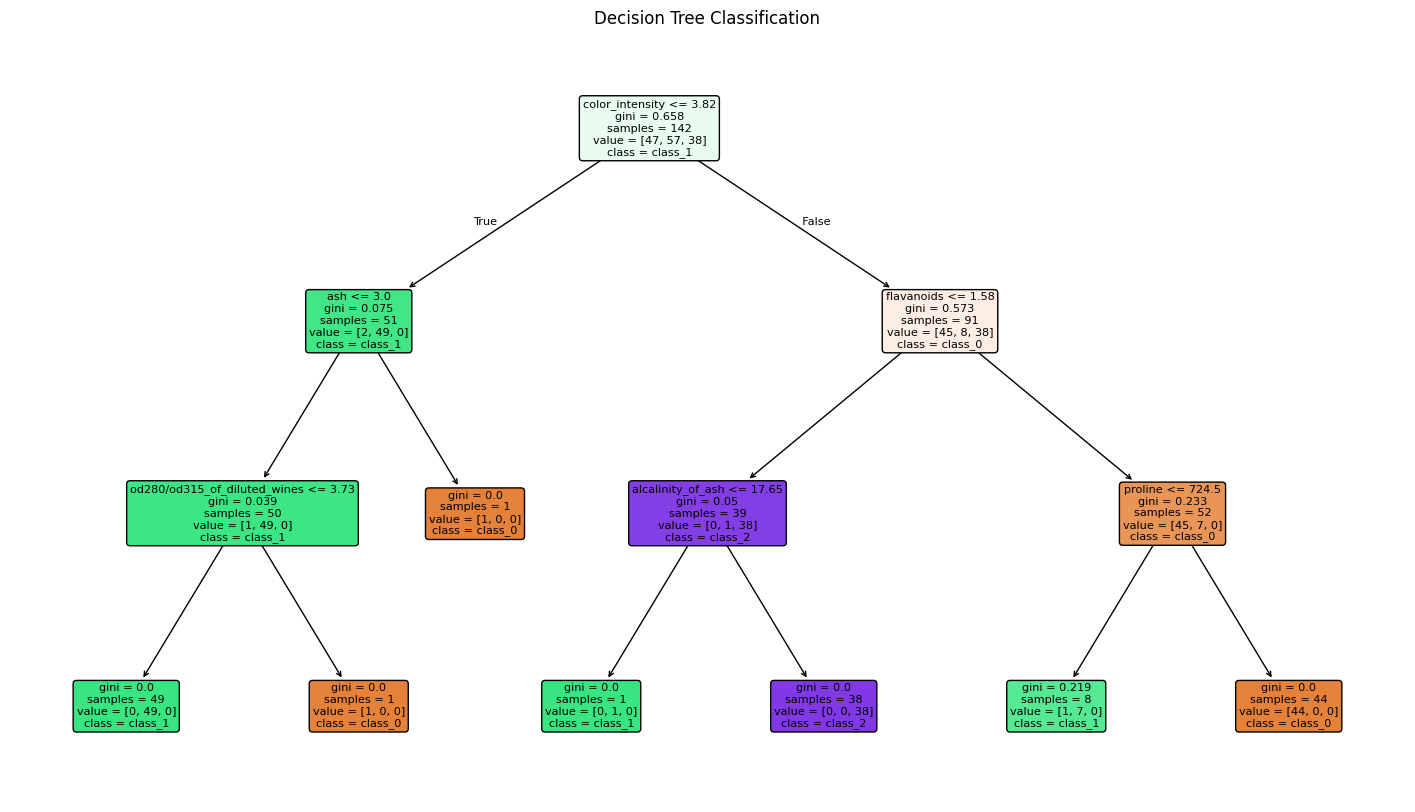

In [3]:

# Experiment 7: Naive Bayes and Memorization Methods for Classification

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Load Wine Dataset
wine = load_wine()

X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

print("Wine Dataset:")
print(X.head())

print("\nTarget Classes:", wine.target_names)

# 2. Split Dataset into Training and Testing Sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Standardize Features for KNN
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Create Models
models = {
    "Gaussian Naive Bayes": GaussianNB(),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=42)
}

# 5. Train and Compare Models
results = []

for name, model in models.items():

    if name == "KNN (k=5)":
        model.fit(X_train_scaled, y_train)
        train_pred = model.predict(X_train_scaled)
        test_pred = model.predict(X_test_scaled)
        cv_scores = cross_val_score(
            KNeighborsClassifier(n_neighbors=5),
            scaler.fit_transform(X),
            y, cv=5
        )

    else:
        model.fit(X_train, y_train)
        train_pred = model.predict(X_train)
        test_pred = model.predict(X_test)
        cv_scores = cross_val_score(model, X, y, cv=5)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)
    cv_acc = cv_scores.mean()

    results.append([name, train_acc, test_acc, cv_acc])

# 6. Display Model Comparison
result_df = pd.DataFrame(
    results,
    columns=["Model", "Training Accuracy", "Test Accuracy",
             "5-Fold CV Accuracy"]
)

print("\nModel Comparison:")
print(result_df.to_string(index=False))

# 7. Select Best Model Using Cross-Validation Accuracy
best_index = result_df["5-Fold CV Accuracy"].idxmax()
best_name = result_df.loc[best_index, "Model"]

print("\nBest Model:", best_name)

# 8. Evaluate Selected Model
best_model = models[best_name]

if best_name == "KNN (k=5)":
    y_pred = best_model.predict(X_test_scaled)
else:
    y_pred = best_model.predict(X_test)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, target_names=wine.target_names
))

# 9. Study Effect of Different K Values in KNN
k_values = range(1, 16)
train_scores = []
test_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train_scaled, y_train)

    train_scores.append(
        accuracy_score(y_train, knn.predict(X_train_scaled))
    )

    test_scores.append(
        accuracy_score(y_test, knn.predict(X_test_scaled))
    )

print("\nKNN Accuracy for Different K Values:")

for k, score in zip(k_values, test_scores):
    print("K =", k, "Test Accuracy =", round(score, 4))

# Plot KNN Accuracy
plt.plot(k_values, train_scores, marker='o', label='Training Accuracy')
plt.plot(k_values, test_scores, marker='s', label='Testing Accuracy')

plt.xlabel("Number of Neighbours (K)")
plt.ylabel("Accuracy")
plt.title("Effect of K in KNN")
plt.legend()
plt.grid()
plt.show()

# 10. Display Decision Tree Rules
tree = models["Decision Tree"]

print("\nDecision Tree Rules:")
print(export_text(tree, feature_names=list(X.columns)))

# 11. Plot Decision Tree
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 10))

plot_tree(
    tree,
    feature_names=wine.feature_names,
    class_names=wine.target_names,
    filled=True,
    rounded=True
)

plt.title("Decision Tree Classification")
plt.show()


Customer Dataset:
    Annual Income  Spending Score
0              15              39
1              16              81
2              17               6
3              18              77
4              19              40
5              20              76
6              22              94
7              23               5
8              25              73
9              28              14
10             30              65
11             32              42
12             35              80
13             38              35
14             40              60
15             42              45
16             45              85
17             48              20
18             50              55
19             52              30
20             55              90
21             58              15
22             60              70
23             62              25
24             65              88
25             68              10
26             70              65
27             72             

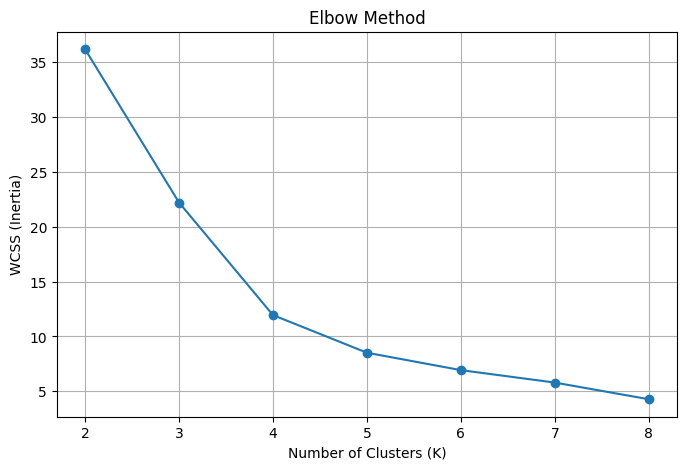

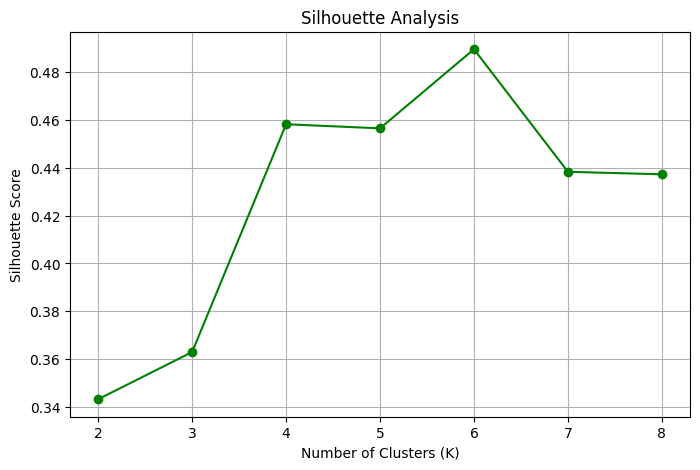


Best K based on Silhouette Score: 6

Customer Cluster Profiles:
         Annual Income  Spending Score  Customer Count
Cluster                                               
0            40.400000       47.400000               5
1            17.000000       39.500000               2
2            61.666667       78.833333               6
3            62.571429       21.428571               7
4            22.666667        8.333333               3
5            23.714286       78.000000               7


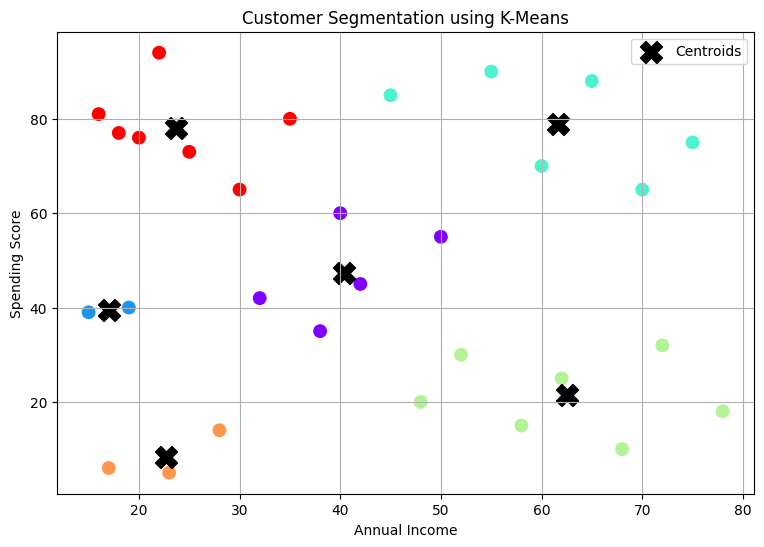


Customer Segment Description:

Cluster: 0
Average Income: 40.4
Average Spending Score: 47.4
Segment: Low Income - Low Spending

Cluster: 1
Average Income: 17.0
Average Spending Score: 39.5
Segment: Low Income - Low Spending

Cluster: 2
Average Income: 61.67
Average Spending Score: 78.83
Segment: High Income - High Spending

Cluster: 3
Average Income: 62.57
Average Spending Score: 21.43
Segment: High Income - Low Spending

Cluster: 4
Average Income: 22.67
Average Spending Score: 8.33
Segment: Low Income - Low Spending

Cluster: 5
Average Income: 23.71
Average Spending Score: 78.0
Segment: Low Income - High Spending


In [4]:

# Experiment 8: K-Means Clustering for Customer Segmentation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Create Customer Dataset
data = {
    'Annual Income': [
        15, 16, 17, 18, 19, 20, 22, 23, 25, 28,
        30, 32, 35, 38, 40, 42, 45, 48, 50, 52,
        55, 58, 60, 62, 65, 68, 70, 72, 75, 78
    ],
    'Spending Score': [
        39, 81, 6, 77, 40, 76, 94, 5, 73, 14,
        65, 42, 80, 35, 60, 45, 85, 20, 55, 30,
        90, 15, 70, 25, 88, 10, 65, 32, 75, 18
    ]
}

df = pd.DataFrame(data)

print("Customer Dataset:")
print(df)

# 2. Standardise Features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# 3. Run K-Means for K = 2 to 8
wcss = []
silhouette_scores = []

for k in range(2, 9):

    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    wcss.append(kmeans.inertia_)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print("\nK =", k)
    print("WCSS:", round(kmeans.inertia_, 2))
    print("Silhouette Score:", round(score, 4))

# 4. Display Elbow Curve
k_values = range(2, 9)

plt.figure(figsize=(8, 5))
plt.plot(k_values, wcss, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method")
plt.grid()
plt.show()

# 5. Display Silhouette Scores
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker='o', color='green')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")
plt.grid()
plt.show()

# 6. Select Best K Using Silhouette Score
best_k = list(k_values)[np.argmax(silhouette_scores)]

print("\nBest K based on Silhouette Score:", best_k)

# 7. Apply Final K-Means Model
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

# 8. Cluster Profiling
print("\nCustomer Cluster Profiles:")

profile = df.groupby('Cluster').agg({
    'Annual Income': 'mean',
    'Spending Score': 'mean',
    'Cluster': 'count'
})

profile.rename(columns={
    'Cluster': 'Customer Count'
}, inplace=True)

print(profile)

# 9. Plot Clusters and Centroids
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(9, 6))

plt.scatter(
    df['Annual Income'],
    df['Spending Score'],
    c=df['Cluster'],
    cmap='rainbow',
    s=80
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    color='black',
    marker='X',
    s=250,
    label='Centroids'
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer Segmentation using K-Means")
plt.legend()
plt.grid()
plt.show()

# 10. Describe Customer Segments
print("\nCustomer Segment Description:")

for cluster in sorted(df['Cluster'].unique()):

    group = df[df['Cluster'] == cluster]

    income = group['Annual Income'].mean()
    spending = group['Spending Score'].mean()

    print("\nCluster:", cluster)

    print("Average Income:", round(income, 2))
    print("Average Spending Score:", round(spending, 2))

    if income >= df['Annual Income'].mean() and spending >= df['Spending Score'].mean():
        print("Segment: High Income - High Spending")

    elif income >= df['Annual Income'].mean():
        print("Segment: High Income - Low Spending")

    elif spending >= df['Spending Score'].mean():
        print("Segment: Low Income - High Spending")

    else:
        print("Segment: Low Income - Low Spending")
